# FungiTastic — Mycologist's EDA

**Prerequisite:** run ingestion + validation first:
```
uv run python -m fungai.data.ingest --subset mini --size 300
uv run python -m fungai.data.validate --subset mini --quick
```
This notebook is graphs + narrative only; correctness checks live in `fungai.data.validate`.

Each section tests hypotheses from the mycology literature (Rustøen 2023 wood-decay substrate affinity;
Andrew et al. 2018 *Ecology* pan-European fruiting phenology; Kauserud et al. 2008 phenology drift;
2023 *Clinical Toxicology* app study; European poisoning case data).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from fungai.data.ingest import DEFAULT_DEST, load_metadata

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=FutureWarning)

# Metadata for the FULL dataset if its CSVs are in metadata.zip, else Mini.
def load_splits(subset):
    out = {}
    for split in ("train", "val", "test"):
        try:
            out[split] = load_metadata(subset, split)
        except FileNotFoundError:
            pass
    return out

splits = load_splits("full")
SUBSET = "full"
if not splits:
    splits, SUBSET = load_splits("mini"), "mini"
mini_splits = load_splits("mini")

df = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)
print(f"metadata-level EDA subset: {SUBSET}")
for s, d in splits.items():
    print(f"  {s:>6}: {len(d):>8,} rows")
print(f"columns: {sorted(df.columns.tolist())}")

metadata-level EDA subset: full
   train:  433,702 rows
     val:   89,659 rows
    test:   91,832 rows
columns: ['biogeo_zone', 'category_id', 'class', 'coorUncert', 'country', 'date', 'day', 'district', 'elevation', 'family', 'filename', 'genus', 'habitat', 'hasCoordinate', 'image_path', 'iucnRedListCategory', 'kingdom', 'land_cover', 'latitude', 'longitude', 'metaSubstrate', 'month', 'observation_id', 'order', 'phylum', 'region', 'scientificName', 'species', 'specificEpithet', 'split', 'substrate', 'toxicity', 'year']


## A. Census & structure

Multi-view photos of one specimen matter: literature says a gills/stem-base view is often what
makes a photo identifiable at all. The long tail tells us how much of the dataset is few-shot.

778 of 2,786 species (27.9%) hold 80% of images
species with <5 images: 0 (0.0%)


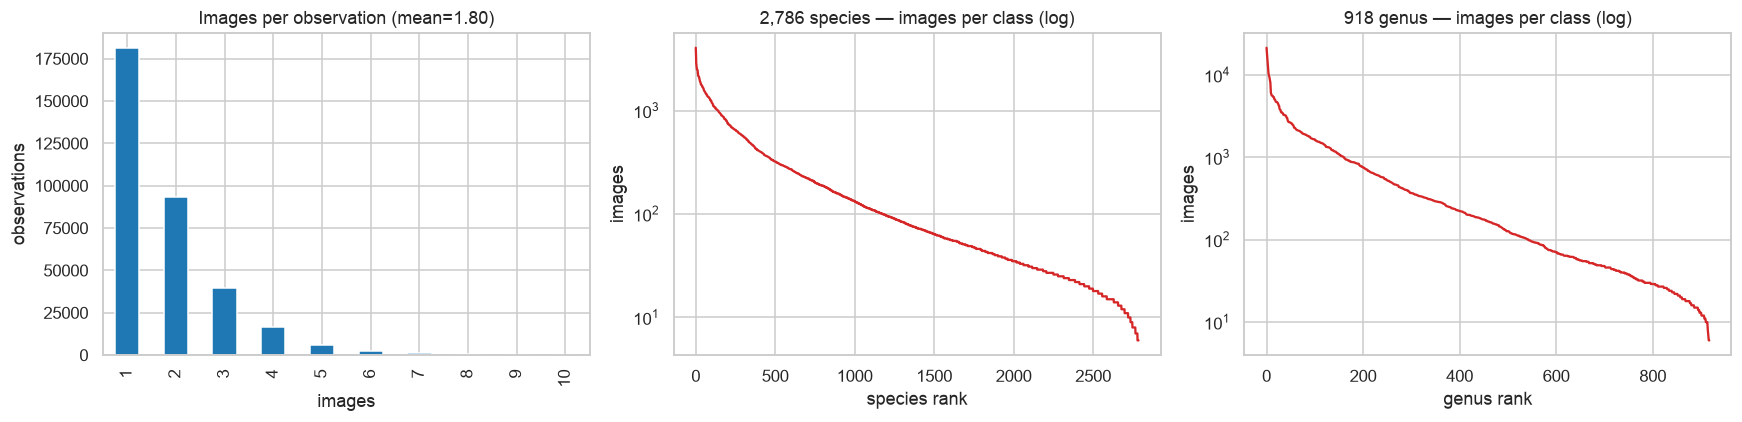

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

if "observation_id" in df.columns:
    ipo = df.groupby("observation_id").size()
    ipo.value_counts().sort_index().head(10).plot.bar(ax=axes[0], color="tab:blue")
    axes[0].set(title=f"Images per observation (mean={ipo.mean():.2f})",
                xlabel="images", ylabel="observations")

for level, ax in (("species", axes[1]), ("genus", axes[2])):
    if level in df.columns:
        counts = df[level].value_counts()
        counts.reset_index(drop=True).plot(ax=ax, logy=True, color="tab:red")
        ax.set(title=f"{counts.size:,} {level} — images per class (log)",
               xlabel=f"{level} rank", ylabel="images")
plt.tight_layout()

if "species" in df.columns:
    counts = df["species"].value_counts()
    cum = counts.cumsum() / counts.sum()
    n80 = (cum <= 0.80).sum()
    print(f"{n80:,} of {counts.size:,} species ({n80/counts.size:.1%}) hold 80% of images")
    print(f"species with <5 images: {(counts < 5).sum():,} ({(counts < 5).mean():.1%})")

## B. Taxonomy & danger

Genera containing both edible and poisonous members are the dangerous look-alike zones.
Death cap (*Amanita phalloides*) causes 80–95% of European fatal poisonings; the table below
tracks the documented real-world confusion pairs.

In [3]:
if {"genus", "toxicity"} <= set(df.columns):
    tox = df.dropna(subset=["genus"]).copy()
    gen = tox.groupby("genus", observed=True)["toxicity"].agg(["nunique", "count"])
    mixed = gen[gen["nunique"] > 1].sort_values("count", ascending=False)
    print(f"genera with BOTH edible and poisonous species: {len(mixed)}")
    display(mixed.head(15))

    sp = df.dropna(subset=["species"]).groupby("species", observed=True).agg(
        n_images=("species", "size"),
        toxic=("toxicity", "first"),
    )
    print("\nimage counts: poisonous vs edible species")
    display(sp.groupby("toxic")["n_images"].describe().round(1))
else:
    print("toxicity/genus columns not resolved — inspect df.columns and update COLUMNS in ingest.py")

genera with BOTH edible and poisonous species: 22


,nunique,count
genus,,
Russula,2,21446
Mycena,2,17896
Lactarius,2,14359
Amanita,2,10610
Cortinarius,2,9809
Tricholoma,2,8723
Agaricus,2,8041
Entoloma,2,5606
Clitocybe,2,5420



image counts: poisonous vs edible species


,count,mean,std,min,25%,50%,75%,max
toxic,,,,,,,,
0,2731.0,215.5,375.1,6.0,31.0,72.0,216.5,4058.0
1,55.0,485.8,590.7,16.0,132.0,274.0,593.0,3337.0


In [4]:
# Documented European confusion pairs (poisoning case literature)
CONFUSION_PAIRS = [
    ("Amanita phalloides",  "Macrolepiota procera"),
    ("Amanita phalloides",  "Russula virescens"),
    ("Amanita phalloides",  "Tricholoma equestre"),
    ("Amanita virosa",      "Agaricus campestris"),
    ("Amanita virosa",      "Agaricus arvensis"),
    ("Galerina marginata",  "Kuehneromyces mutabilis"),
    ("Cortinarius rubellus","Craterellus tubaeformis"),
]

def hist_overlap(a, b, col, bins=None):
    """Histogram intersection in [0,1]: 1 = identical metadata distributions."""
    if col not in df.columns:
        return np.nan
    pa = a[col].value_counts(normalize=True)
    pb = b[col].value_counts(normalize=True)
    idx = pa.index.union(pb.index)
    return float(np.minimum(pa.reindex(idx, fill_value=0), pb.reindex(idx, fill_value=0)).sum())

rows = []
if "species" in df.columns:
    have = set(df["species"].dropna().unique())
    for tox_sp, edible_sp in CONFUSION_PAIRS:
        if tox_sp not in have or edible_sp not in have:
            rows.append({"toxic": tox_sp, "edible": edible_sp, "in_dataset": False})
            continue
        a, b = df[df["species"] == tox_sp], df[df["species"] == edible_sp]
        rows.append({
            "toxic": tox_sp, "edible": edible_sp, "in_dataset": True,
            "n_toxic": len(a), "n_edible": len(b),
            "month_overlap": hist_overlap(a, b, "month"),
            "habitat_overlap": hist_overlap(a, b, "habitat"),
            "substrate_overlap": hist_overlap(a, b, "substrate"),
        })
pairs_df = pd.DataFrame(rows)
display(pairs_df)
print("High overlap on all three columns => metadata can't separate the pair; "
      "images must carry everything. These pairs anchor cost-sensitive evaluation later.")

,toxic,edible,in_dataset,n_toxic,n_edible,month_overlap,habitat_overlap,substrate_overlap
0,Amanita phalloides,Macrolepiota procera,True,911,1084,0.788144,0.305878,0.956694
1,Amanita phalloides,Russula virescens,True,911,373,0.587208,0.780844,0.957063
2,Amanita phalloides,Tricholoma equestre,True,911,222,0.348390,0.139600,0.958401
3,Amanita virosa,Agaricus campestris,True,554,986,0.669759,0.036976,0.938852
4,Amanita virosa,Agaricus arvensis,True,554,924,0.547002,0.139982,0.954866
5,Galerina marginata,Kuehneromyces mutabilis,True,961,1907,0.637472,0.675067,0.804965
6,Cortinarius rubellus,Craterellus tubaeformis,True,327,1046,0.433400,0.817715,0.831141


High overlap on all three columns => metadata can't separate the pair; images must carry everything. These pairs anchor cost-sensitive evaluation later.


## C. Ecology as signal

**Core question: how much does context narrow the field before a single pixel is seen?**

- **H1** substrate × genus MI high; wood-decay structured by wood type, not climate (Rustøen 2023)
- **H2** habitat separates species *within* ECM genera better than it separates genera
- **H3** tight 2–3-month fruiting windows separate congeners; year-on-year drift exists
- **H4** precipitation in a 7–60-day pre-observation window separates guilds (Andrew 2018)
- **H5** elevation/biogeo/land-cover add signal over habitat alone

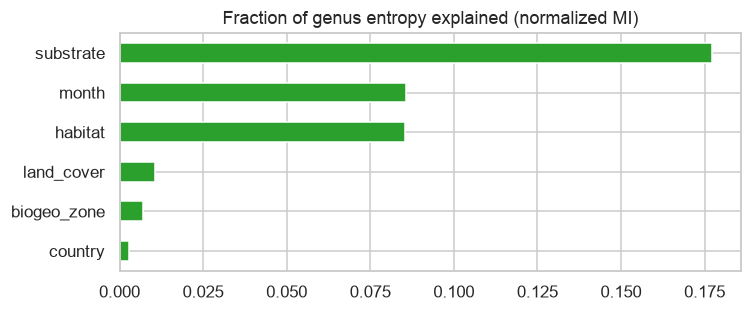

In [5]:
# H1: how much does each metadata field alone tell us about genus?
from sklearn.metrics import mutual_info_score

def norm_mi(x, y):
    """MI normalized by H(y): fraction of genus entropy explained."""
    m = pd.DataFrame({"x": x, "y": y}).dropna()
    if m.empty:
        return np.nan
    mi = mutual_info_score(m["x"], m["y"])
    py = m["y"].value_counts(normalize=True)
    hy = -(py * np.log(py)).sum()
    return mi / hy if hy else np.nan

fields = [c for c in ("substrate", "habitat", "month", "biogeo_zone",
                      "land_cover", "country") if c in df.columns]
if "genus" in df.columns:
    mi_scores = pd.Series({f: norm_mi(df[f], df["genus"]) for f in fields}).sort_values()
    mi_scores.plot.barh(figsize=(7, 3), color="tab:green",
                        title="Fraction of genus entropy explained (normalized MI)")
    plt.tight_layout()

In [6]:
# H1b: near-deterministic substrate -> genus pairs = hard priors
if {"substrate", "genus"} <= set(df.columns):
    ct = pd.crosstab(df["substrate"], df["genus"])
    top = ct.div(ct.sum(axis=1), axis=0)
    strong = []
    for substrate in top.index:
        best = top.loc[substrate].idxmax()
        p = top.loc[substrate, best]
        n = ct.loc[substrate].sum()
        if p > 0.5 and n >= 50:
            strong.append({"substrate": substrate, "genus": best,
                           "P(genus|substrate)": round(float(p), 3), "n_obs": int(n)})
    strong_df = pd.DataFrame(strong).sort_values("P(genus|substrate)", ascending=False)
    print("substrates where one genus takes >50% of observations:")
    display(strong_df.head(20))

substrates where one genus takes >50% of observations:


,substrate,genus,P(genus|substrate),n_obs
1,insects,Cordyceps,0.825,639
2,liverworts,Mniaecia,0.692,120
0,catkins,Ciboria,0.569,554
3,living flowers,Microbotryum,0.544,439


In [7]:
# H2: does habitat separate species WITHIN ECM genera better than genera overall?
ECM_GENERA = ["Russula", "Amanita", "Boletus", "Lactarius", "Cortinarius", "Suillus", "Leccinum"]
if {"habitat", "genus", "species"} <= set(df.columns):
    overall = norm_mi(df["habitat"], df["genus"])
    print(f"habitat->genus normalized MI (all data): {overall:.3f}")
    rows = []
    for g in ECM_GENERA:
        sub = df[df["genus"] == g]
        if len(sub) > 200 and sub["species"].nunique() > 3:
            rows.append({"genus": g, "n": len(sub),
                         "n_species": sub["species"].nunique(),
                         "habitat->species MI (within genus)": round(norm_mi(sub["habitat"], sub["species"]), 3)})
    display(pd.DataFrame(rows))
    print("H2 supported if within-genus MI > overall genus-level MI")

habitat->genus normalized MI (all data): 0.085


,genus,n,n_species,habitat->species MI (within genus)
0,Russula,21446,88,0.137
1,Amanita,10610,19,0.101
2,Lactarius,14359,55,0.159
3,Cortinarius,9809,89,0.171
4,Suillus,5773,10,0.144
5,Leccinum,4696,10,0.151


H2 supported if within-genus MI > overall genus-level MI


species (n>=100) whose 80% fruiting window is <=3 months: 50.7% of 1181


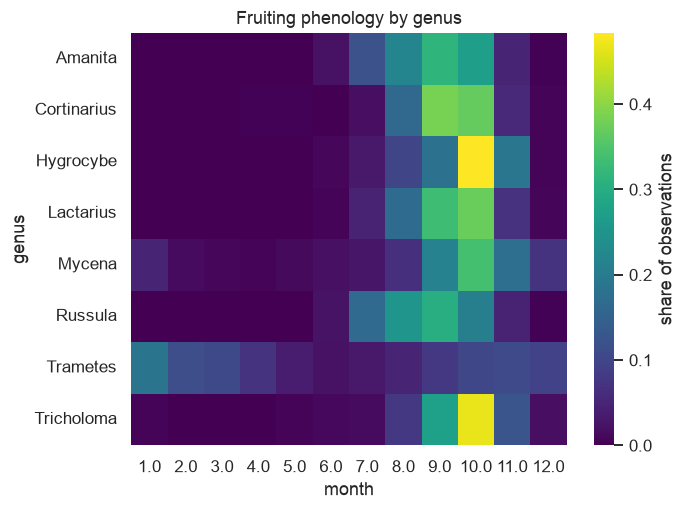

In [8]:
# H3: phenology — month distributions per genus + top species windows
if {"month", "genus"} <= set(df.columns):
    top_genera = df["genus"].value_counts().head(8).index
    pheno = (df[df["genus"].isin(top_genera)]
             .groupby(["genus", "month"], observed=True).size().unstack(fill_value=0))
    pheno = pheno.div(pheno.sum(axis=1), axis=0)
    sns.heatmap(pheno, cmap="viridis", cbar_kws={"label": "share of observations"})
    plt.title("Fruiting phenology by genus")
    plt.tight_layout()

if {"month", "species"} <= set(df.columns):
    sp_counts = df["species"].value_counts()
    big = sp_counts[sp_counts >= 100].index
    widths = (df[df["species"].isin(big)]
              .groupby("species", observed=True)["month"]
              .agg(lambda m: (m.value_counts(normalize=True)
                              .sort_values(ascending=False).cumsum() <= 0.8).sum() + 1))
    print(f"species (n>=100) whose 80% fruiting window is <=3 months: "
          f"{(widths <= 3).mean():.1%} of {len(widths)}")

trend: 0.1 days/year shift


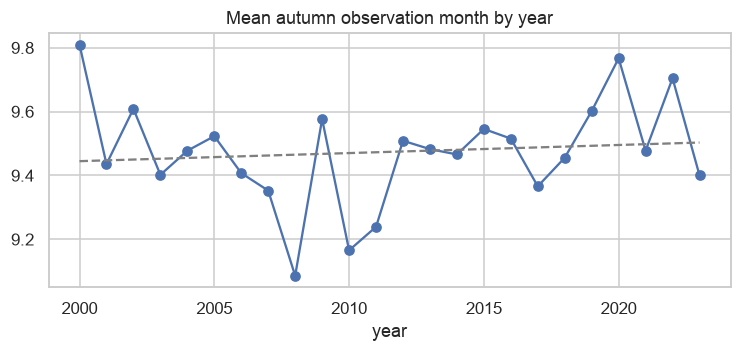

In [9]:
# H3b: year-on-year fruiting drift (chronological-split risk)
if {"year", "month", "genus"} <= set(df.columns):
    autumn = df[df["month"].isin([8, 9, 10, 11])].dropna(subset=["year"])
    drift = autumn.groupby("year")["month"].mean()
    drift = drift[drift.index >= 2000]
    if len(drift) > 5:
        ax = drift.plot(marker="o", figsize=(8, 3), title="Mean autumn observation month by year")
        z = np.polyfit(drift.index, drift.values, 1)
        ax.plot(drift.index, np.polyval(z, drift.index), "--", color="gray")
        print(f"trend: {z[0]*30:.1f} days/year shift")

In [10]:
# H4: climate windows — exploratory; depends on climatic.zip layout
clim_dir = DEFAULT_DEST / "climate"
if clim_dir.exists():
    files = sorted(clim_dir.rglob("*"))[:20]
    print("climate files sample:")
    for f in files:
        print("  ", f.relative_to(clim_dir), f.stat().st_size if f.is_file() else "<dir>")
    csvs = [f for f in clim_dir.rglob("*.csv")][:1]
    if csvs:
        clim = pd.read_csv(csvs[0], nrows=5)
        print(f"\n{csvs[0].name} columns: {clim.columns.tolist()[:30]}")
        # TODO once schema known: cumulative precipitation at 7–60-day lags vs genus separation
else:
    print("climate/ not downloaded — H4 deferred")

climate/ not downloaded — H4 deferred


top country holds 98.7% of data — record as deployment-generalization risk


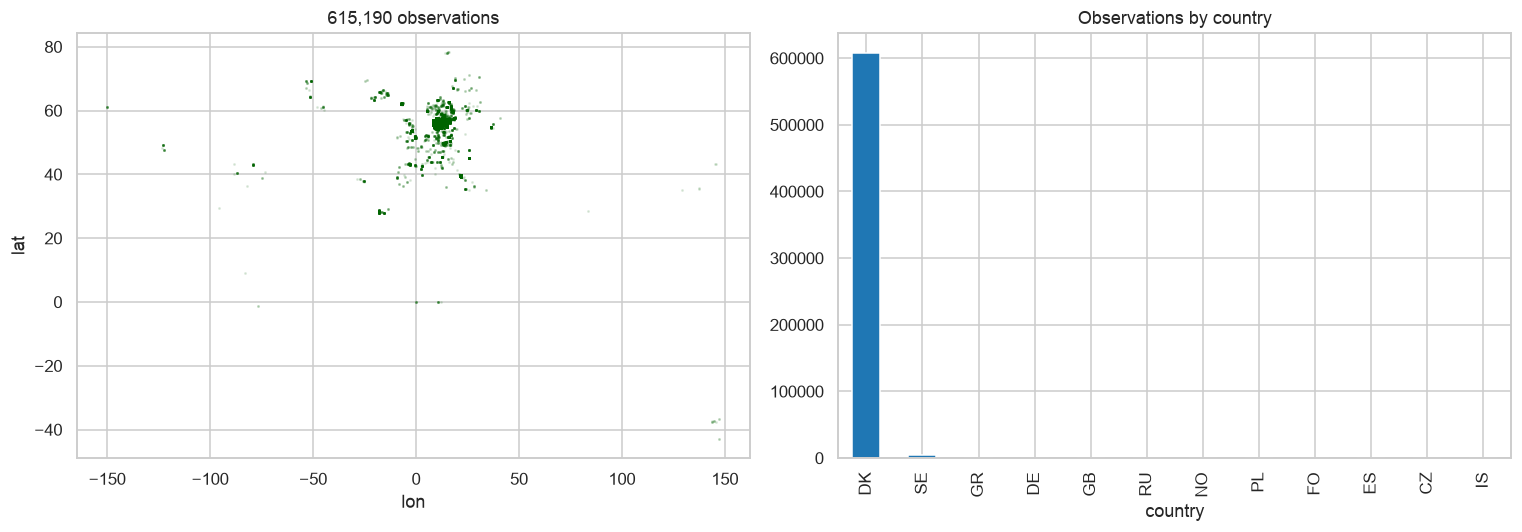

In [11]:
# Geography: observation map + the dataset's geographic bias
if {"latitude", "longitude"} <= set(df.columns):
    geo = df.dropna(subset=["latitude", "longitude"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(geo["longitude"], geo["latitude"], s=1, alpha=0.1, color="darkgreen")
    axes[0].set(title=f"{len(geo):,} observations", xlabel="lon", ylabel="lat")
    if "country" in df.columns:
        df["country"].value_counts().head(12).plot.bar(ax=axes[1], color="tab:blue",
                                                       title="Observations by country")
    plt.tight_layout()
    if "country" in df.columns:
        top_share = df["country"].value_counts(normalize=True).iloc[0]
        print(f"top country holds {top_share:.1%} of data — record as deployment-generalization risk")

In [12]:
# THE CONTEXT FLOOR: metadata-only classifier (no pixels)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

FEATURES = [c for c in ("month", "latitude", "longitude", "elevation",
                        "habitat", "substrate", "land_cover", "biogeo_zone") if c in df.columns]

def prep(d, target):
    X = d[FEATURES].copy()
    for c in X.columns:
        if X[c].dtype == "category" or X[c].dtype == object:
            X[c] = X[c].astype("category")
        else:
            X[c] = pd.to_numeric(X[c], errors="coerce")
    return X, d[target]

results = {}
if {"train", "val"} <= set(splits) and "genus" in df.columns:
    for target in [t for t in ("genus", "species") if t in df.columns]:
        tr, va = splits["train"].dropna(subset=[target]), splits["val"].dropna(subset=[target])
        va = va[va[target].isin(tr[target].unique())]  # closed-set floor
        Xtr, ytr = prep(tr, target)
        Xva, yva = prep(va, target)
        clf = HistGradientBoostingClassifier(categorical_features="from_dtype",
                                             max_iter=200, random_state=0)
        clf.fit(Xtr, ytr.astype(str))
        acc = clf.score(Xva, yva.astype(str))
        base = yva.value_counts(normalize=True).iloc[0]
        results[target] = (clf, Xva, yva, acc, base)
        print(f"metadata-only {target} accuracy: {acc:.1%}  "
              f"(majority-class baseline: {base:.1%}, {ytr.nunique()} classes)")
else:
    print("need train+val splits with genus labels")

metadata-only genus accuracy: 1.1%  (majority-class baseline: 3.1%, 918 classes)


KeyboardInterrupt: 

In [ ]:
# Which context signals carry the weight? (permutation importance, genus model)
if "genus" in results:
    clf, Xva, yva, _, _ = results["genus"]
    samp = Xva.sample(min(5000, len(Xva)), random_state=0)
    imp = permutation_importance(clf, samp, yva.loc[samp.index].astype(str),
                                 n_repeats=3, random_state=0)
    (pd.Series(imp.importances_mean, index=FEATURES).sort_values()
       .plot.barh(figsize=(7, 3), color="tab:purple",
                  title="Permutation importance — metadata-only genus model"))
    plt.tight_layout()

## D. Images & masks (Mini) — photo-identifiability limits

Many taxa are fundamentally unidentifiable from a cap-only photo (>70% of iNat fungal
observations never reach research grade). Russula is the canonical microscopy-required genus —
expect it ceiling-limited.

In [ ]:
import torch
from fungai.data import FungiDataset
from fungai.viz import show_batch

try:
    ds = FungiDataset.from_split("mini", "train")
    print(f"Mini train: {len(ds):,} images")
    idx = np.random.default_rng(0).choice(len(ds), 16, replace=False)
    samples = [ds[int(i)] for i in idx]
    show_batch(torch.stack([s["image"] for s in samples]),
               labels=[str(s["species"])[:22] for s in samples], ncol=8)
except Exception as exc:
    print(f"image section skipped: {exc}")

In [ ]:
# Toxic vs edible congeners, side by side (first resolvable confusion pair)
if "species" in df.columns and "mini" in (SUBSET, "mini") and mini_splits:
    mdf = pd.concat(mini_splits.values(), ignore_index=True)
    have = set(mdf.get("species", pd.Series(dtype=object)).dropna())
    for tox_sp, ed_sp in CONFUSION_PAIRS:
        if tox_sp in have and ed_sp in have and "image_path" in mdf.columns:
            fig, axes = plt.subplots(2, 6, figsize=(15, 5))
            for row, sp_name in enumerate((tox_sp, ed_sp)):
                paths = mdf.loc[mdf["species"] == sp_name, "image_path"].head(6)
                for ax, p in zip(axes[row], paths):
                    from PIL import Image as PILImage
                    ax.imshow(PILImage.open(p)); ax.axis("off")
                axes[row][0].set_ylabel(sp_name, fontsize=9)
            fig.suptitle(f"TOXIC {tox_sp}  vs  edible {ed_sp}")
            plt.tight_layout()
            break

In [ ]:
# Masks: RLE part-segmentations in parquet (label = body part, file_name, width, height, rle)
masks_dir = DEFAULT_DEST / "masks"
if masks_dir.exists() and list(masks_dir.glob("*.parquet")):
    masks = pd.read_parquet(masks_dir / "FungiTastic-Mini-TrainMasks.parquet",
                            columns=["label", "file_name"])
    print(f"{len(masks):,} part-masks over {masks['file_name'].nunique():,} images")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    masks["label"].value_counts().plot.barh(ax=axes[0], color="tab:orange",
                                            title="Annotated body parts (train)")

    # Per-genus part visibility: what fraction of each genus's photos show gills/stem?
    if mini_splits and "train" in mini_splits:
        mtr = mini_splits["train"]
        parts_per_img = masks.groupby("file_name")["label"].agg(set)
        vis = mtr[["filename", "genus"]].copy()
        vis["parts"] = vis["filename"].map(parts_per_img)
        vis = vis.dropna(subset=["parts"])
        key_parts = [p for p in ("gills", "stem", "cap", "ring", "pores") 
                     if any(p in s for s in parts_per_img.head(500))]
        rates = {}
        for g, grp in vis.groupby("genus", observed=True):
            if len(grp) >= 100:
                rates[g] = {p: np.mean([p in s for s in grp["parts"]]) for p in key_parts}
        rates_df = pd.DataFrame(rates).T
        if not rates_df.empty:
            sns.heatmap(rates_df, annot=True, fmt=".2f", cmap="RdYlGn", ax=axes[1],
                        cbar=False)
            axes[1].set_title("P(part visible in photo) by genus")
    plt.tight_layout()
    print("Low gills/stem visibility for a genus -> photos often miss the diagnostic features")
else:
    print("masks/ not downloaded")

In [ ]:
# Image quality: resolution / aspect / device
if mini_splits and "image_path" in next(iter(mini_splits.values())).columns:
    from PIL import Image as PILImage
    mdf = pd.concat(mini_splits.values(), ignore_index=True)
    paths = mdf["image_path"].dropna().sample(min(1000, len(mdf)), random_state=0)
    dims = []
    for p in paths:
        try:
            with PILImage.open(p) as im:
                dims.append(im.size)
        except Exception:
            pass
    dims = pd.DataFrame(dims, columns=["w", "h"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    dims["w"].plot.hist(bins=40, ax=axes[0], title="width (px)")
    (dims["w"] / dims["h"]).plot.hist(bins=40, ax=axes[1], title="aspect ratio")
    plt.tight_layout()

## E. Findings

_Fill in after running top-to-bottom:_

1. **Context floor**: metadata-only genus accuracy = __%, species = __% (vs majority baselines). Ranked signals: …
2. **Hard priors**: near-deterministic substrate→genus pairs: …
3. **Confusion pairs**: which documented toxic/edible pairs have high metadata overlap (images must do the work): …
4. **Phenology**: share of species with ≤3-month fruiting windows: __%; drift: __ days/year
5. **Data risks**: __% of species hold 80% of images; top country = __%; data-poor toxic species: …
6. **Architecture implications**: …